In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold
from matplotlib import cm
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA


In [4]:
# file_path = "Data_MN_Model/Data_final/DR_trapezoid_pic.jld2"
# # spikes_exc_newInput
# with h5py.File(file_path, 'r') as f:
#     spike_array_pic = f['spike_array'][:]  # (600000, 87)
    
# file_path = "Data_MN_Model/Data_final/DR_trapezoid_nopic.jld2"
# # spikes_exc_newInput
# with h5py.File(file_path, 'r') as f:
#     spike_array_nopic = f['spike_array'][:]  # (600000, 87)
    
# file_path = "Data_MN_Model/Data_final/Controller/spikes_exc_newInput.jld2"
# with h5py.File(file_path, 'r') as f:
#     spike_array_pic_cont = f['spike_array'][:]  # (600000, 87)
    
file_path = "Data_MN_Model/Data_final/Spikes/DR_subject1_TAgamma1_SINUSOID_PIC.jld2"
with h5py.File(file_path, 'r') as f:
    spike_array_pic = f['spike_array'][:]  # (600000, 87)
    
    file_path = "Data_MN_Model/Data_final/Spikes/DR_subject1_TAgamma1_SINUSOID_NOPIC.jld2"
with h5py.File(file_path, 'r') as f:
    spike_array_nopic = f['spike_array'][:]  # (600000, 87)

In [3]:
spike_array_pic.shape

(100000, 181)

In [18]:
window_size_ms = 150  # 300 ms window
sampling_rate = 20000  # 20 kHz
window_size_samples = int((window_size_ms / 1000) * sampling_rate)  # Convert window size to samples

smoothed_spike_array_pic = np.zeros_like(spike_array_pic)
smoothed_spike_array_nopic = np.zeros_like(spike_array_nopic)

# moving average over each neuron's spike train
for neuron in range(spike_array_pic.shape[1]):
    smoothed_spike_array_pic[:, neuron] = gaussian_filter1d(spike_array_pic[:, neuron], sigma=(window_size_samples / 6))
    smoothed_spike_array_nopic[:, neuron] = gaussian_filter1d(spike_array_nopic[:, neuron], sigma=(window_size_samples / 6))


In [19]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Assuming smoothed_spike_array_pic is your smoothed spike data array with shape (samples, neurons)

# Standardize the data (each neuron's activity across samples)
scaler = StandardScaler()
smoothed_spike_array_pic_scaled = scaler.fit_transform(smoothed_spike_array_pic)

# Apply PCA and retain only the first component
pca = PCA(n_components=5)
pca.fit(smoothed_spike_array_pic_scaled)

# Print explained variance for the first principal component
explained_variance_first_component = pca.explained_variance_ratio_[0]
print("Explained Variance of the First Principal Component:", explained_variance_first_component)


Explained Variance of the First Principal Component: 0.793373784620675


In [15]:
scaler = StandardScaler()
smoothed_spike_array_nopic_scaled = scaler.fit_transform(smoothed_spike_array_nopic)

# Apply PCA and retain only the first component
pca = PCA(n_components=5)
pca.fit(smoothed_spike_array_nopic_scaled)

# Print explained variance for the first principal component
explained_variance_first_component = pca.explained_variance_ratio_[0]
print("Explained Variance of the First Principal Component:", explained_variance_first_component)


Explained Variance of the First Principal Component: 0.6578328658899826


[0.80614785 0.88809989 0.91081205 0.92635485 0.93660807]
[0.82943674 0.90866464 0.9326021  0.94351015 0.95044824]


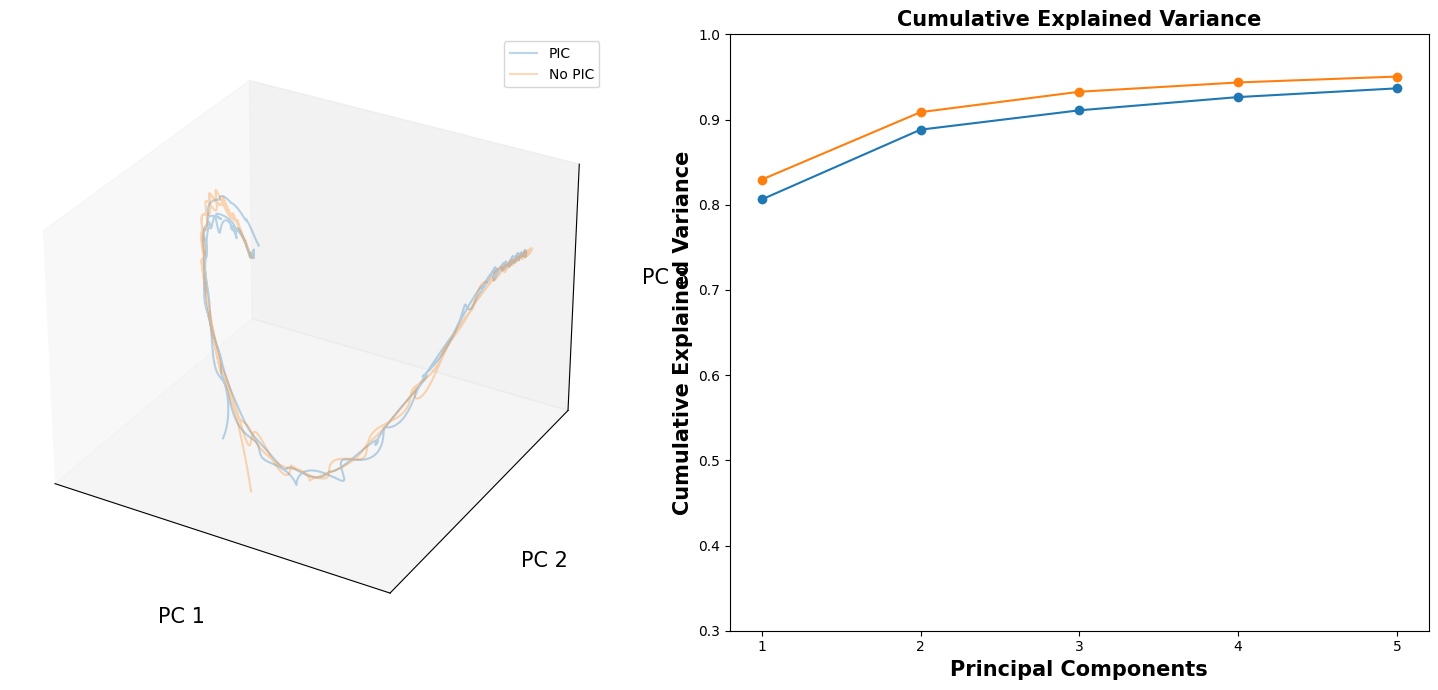

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# Assuming downsampled_spike_array_pic, downsampled_spike_array_pic_controlled, and downsampled_spike_array_nopic are defined

# Perform PCA for PIC case
pca_pic = PCA(n_components=5)
principal_components_pic = pca_pic.fit_transform(smoothed_spike_array_pic)
explained_variance_pic = pca_pic.explained_variance_ratio_
cumulative_explained_variance_pic = np.cumsum(explained_variance_pic)
print(cumulative_explained_variance_pic)
# # # Perform PCA for PIC Controlled case
# pca_piccontrolled = PCA(n_components=5)
# principal_components_piccontrolled = pca_piccontrolled.fit_transform(smoothed_spike_array_nopic)
# explained_variance_piccontrolled = pca_piccontrolled.explained_variance_ratio_
# cumulative_explained_variance_piccontrolled = np.cumsum(explained_variance_piccontrolled)

# Perform PCA for No PIC case
pca_nopiccontrolled = PCA(n_components=5)
principal_components_nopiccontrolled = pca_nopiccontrolled.fit_transform(smoothed_spike_array_nopic)
explained_variance_nopiccontrolled = pca_nopiccontrolled.explained_variance_ratio_
cumulative_explained_variance_nopiccontrolled = np.cumsum(explained_variance_nopiccontrolled)
print(cumulative_explained_variance_nopiccontrolled)
# Create subplots
fig = plt.figure(figsize=(15, 7))

# Subplot 1: 3D PCA plot
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot(principal_components_pic[:, 0], principal_components_pic[:, 1], principal_components_pic[:, 2], alpha=0.3, label='PIC')
# ax1.scatter(principal_components_piccontrolled[:, 0], principal_components_piccontrolled[:, 1], principal_components_piccontrolled[:, 2], alpha=0.7, label='PIC Controlled')
ax1.plot(principal_components_nopiccontrolled[:, 0], principal_components_nopiccontrolled[:, 1], principal_components_nopiccontrolled[:, 2], alpha=0.3, label='No PIC')

# Label the axes with Principal Components
ax1.set_xlabel('PC 1', fontsize=15, labelpad=20)
ax1.set_ylabel('PC 2', fontsize=15, labelpad=20)
ax1.set_zlabel('PC 3', fontsize=15, labelpad=20)

# Hide the ticks (numbers) on the axes
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_zticks([])

# Add legend
ax1.legend()

# Subplot 2: Cumulative explained variance
ax2 = fig.add_subplot(122)

# Plot the cumulative explained variance for each case
ax2.plot(np.arange(1, 6), cumulative_explained_variance_pic, label='PIC', marker='o')
# ax2.plot(np.arange(1, 6), cumulative_explained_variance_piccontrolled, label='PIC Controlled', marker='o')
ax2.plot(np.arange(1, 6), cumulative_explained_variance_nopiccontrolled, label='No PIC', marker='o')

# Label the axes for explained variance plot
ax2.set_xlabel('Principal Components', fontsize=15, fontweight='bold')
ax2.set_ylabel('Cumulative Explained Variance', fontsize=15, fontweight='bold')
ax2.set_title('Cumulative Explained Variance', fontsize=15, fontweight='bold')
ax2.set_ylim([0.3, 1])

# Customize ticks
ax2.set_xticks(np.arange(1, 6))  # Principal components 1 to 5
# ax2.set_yticks(np.linspace(0, 1, 11))  # Explained variance from 0 to 1

# Add legend
# ax2.legend()

# Show the full plot
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/figures/PCA.pdf', dpi=300, bbox_inches='tight')

plt.show()

# Set figure size in inches (convert cm to inches)
fig.set_size_inches(1.97, 2.76)

# Save the figure with the desired size and high resolution



In [25]:
window_size_ms = 500  # 300 ms window
sampling_rate = 20000  # 20 kHz
window_size_samples = int((window_size_ms / 1000) * sampling_rate)  # Convert window size to samples

smoothed_spike_array_pic = np.zeros_like(sin_PICs)
smoothed_spike_array_nopic = np.zeros_like(sin_NOPICs)

# moving average over each neuron's spike train
for neuron in range(sin_PICs.shape[1]):
    smoothed_spike_array_pic[:, neuron] = np.convolve(sin_PICs[:, neuron], np.ones(window_size_samples)/window_size_samples, mode='same')
    smoothed_spike_array_nopic[:, neuron] = np.convolve(sin_NOPICs[:, neuron], np.ones(window_size_samples)/window_size_samples, mode='same')


# downsampling_factor = 1000

# downsampled_spike_array_pic = smoothed_spike_array_pic[::downsampling_factor, :]
# downsampled_spike_array_nopic = smoothed_spike_array_nopic[::downsampling_factor, :]


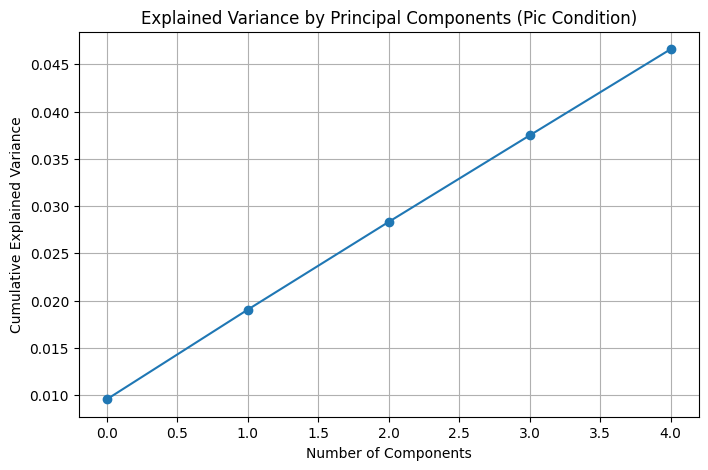

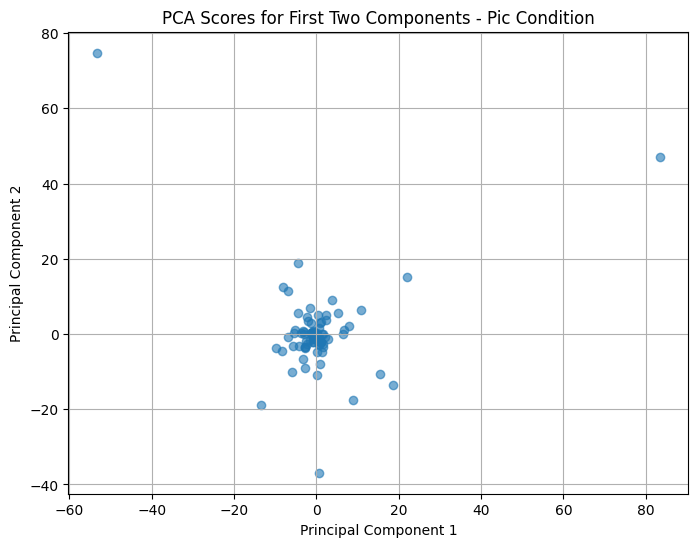

Explained variance for first 5 components (Pic Condition): [0.00957343 0.0094821  0.00928003 0.00914407 0.00911273]


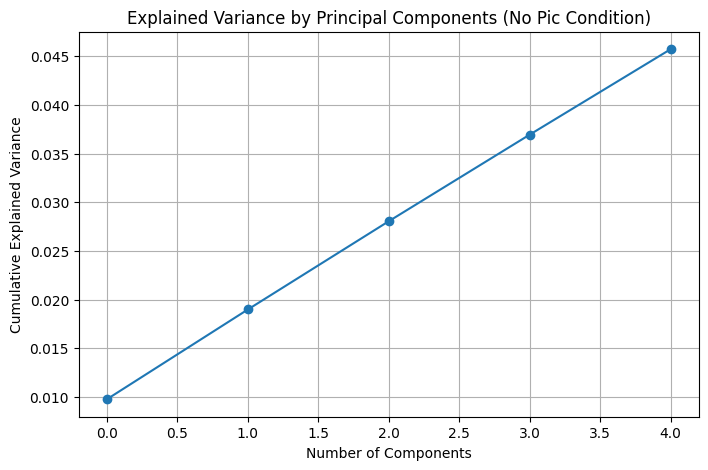

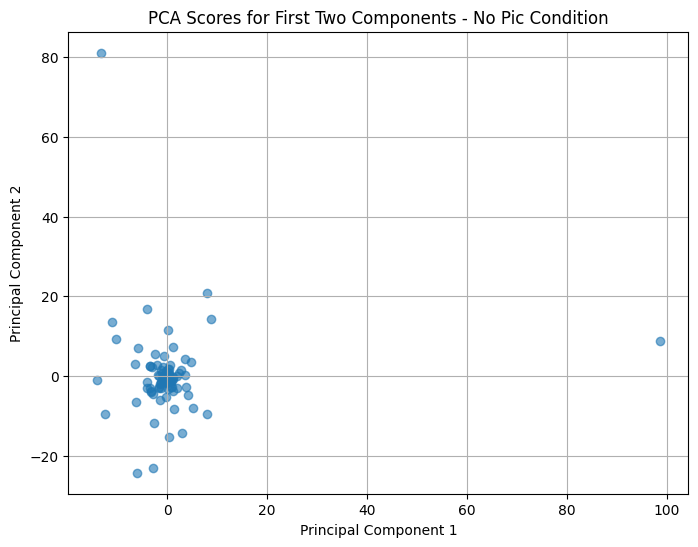

Explained variance for first 5 components (No Pic Condition): [0.00976087 0.00921815 0.0090657  0.00889359 0.00877601]


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Define a function to perform PCA on a single array with a specific number of components
def perform_pca(data_array, condition_name, n_components=None):
    # Normalize the data
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data_array.T).T  # Normalize across neurons
    
    # Apply PCA with specified number of components
    pca = PCA(n_components=n_components)
    pca.fit(data_scaled.T)
    scores = pca.transform(data_scaled.T)
    
    # Plot cumulative explained variance if not limiting components or show only up to n_components
    plt.figure(figsize=(8, 5))
    plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance')
    plt.title(f'Explained Variance by Principal Components ({condition_name})')
    plt.grid()
    plt.show()
    
    # Plot the scores for the first two principal components if more than 1 component was retained
    if n_components is None or n_components > 1:
        plt.figure(figsize=(8, 6))
        plt.scatter(scores[:, 0], scores[:, 1], alpha=0.6)
        plt.xlabel('Principal Component 1')
        plt.ylabel('Principal Component 2')
        plt.title(f'PCA Scores for First Two Components - {condition_name}')
        plt.grid()
        plt.show()
    
    # Print the explained variance for the selected components
    print(f"Explained variance for first {n_components if n_components else 'all'} components ({condition_name}):", pca.explained_variance_ratio_[:n_components])
    
    return scores, pca

# Specify the number of components you want to retain
n_components = 5  # Set to your desired number of components, or None to keep all

# Run PCA separately for each condition with specified number of components
scores_pic, pca_pic = perform_pca(spike_array_pic, "Pic Condition", n_components=n_components)
scores_nopic, pca_nopic = perform_pca(spike_array_nopic, "No Pic Condition", n_components=n_components)
